# Notebook Experimenting with using JAX for GPR

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import scipy
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

For our tests, we will use an additive function over 2-dimensions, and optimise an orthogonal additive kernel (OAK) GP using modified SE base-kernels.

The test function will be,
$$
f(\mathbf{x}) = 3\mathrm{e}^{-x_1^2}\sin(x_1) + \frac{1}{x_2^2 + 1} + \mathrm{e}^{-(x_1^2 +x_2^2)/2}\cos(3x_1)\sin(5x_2).
$$

We will sample our data over a data distribution given by $\mathbf{x} \sim \mathcal{N}(0, I_{2\times 2})$
We will employ the OAK given by Lu et al.,
$$
k(\mathbf{x}, \mathbf{x}') = \sum_{i=0}^2 \sigma_i^2 k_{\mathrm{add}i}(\mathbf{x}, \mathbf{x}'),
$$
with
\begin{align}
k_{\mathrm{add}0}(\mathbf{x}, \mathbf{x}') &= 1,\\
k_{\mathrm{add}1}(\mathbf{x}, \mathbf{x}') &= k_1(x_1, x_1') + k_2(x_2, x_2'),\\
k_{\mathrm{add}2}(\mathbf{x}, \mathbf{x}') &= k_1(x_1, x_1')k_2(x_2, x_2').
\end{align}
and
$$
k_i(x_i, x_i') = \exp\left( -\frac{(x_i - x_i')^2}{2l_i^2}\right)
- \frac{l_i\sqrt{l_i^2 + 2}}{l_i^2 + 1}\exp\left( -\frac{x_i^2 + x_i'^2}{2(l_i^2 + 1)} \right).
$$
We need to optimise over 5 hyperparameters, given by $\Omega = \{ \sigma_0^2, \sigma_1^2, \sigma_2^2, l_1, l_2 \}$, with all values constrained to be positive. For now, we do not employ the efficient Newton-Girard Algorithm because this example lies in 2D.

In [2]:
# Sample data
key = jax.random.key(24)
N = 50
x_mean = jnp.array([0, 0])
x_cov = jnp.array([[1, 0], [0, 1]])
X = jax.random.multivariate_normal(key, x_mean, x_cov, N)

def f(x):
    """Note x = [x1, x2]"""
    term1 = 3 * jnp.exp(-x[0]**2) * jnp.sin(x[0])
    term2 = 1 / (1 + x[1]**2)
    term12 = jnp.exp(-(x[0]**2 + x[1]**2)/2) * jnp.cos(3 * x[0]) * jnp.sin(5 * x[1])
    return term1 + term2 + term12

def f_np(x):
    """Note x = [x1, x2]"""
    x1, x2 = x[..., 0], x[..., 1] # For ease of plotting
    term1 = 3 * np.exp(-x1**2) * np.sin(x1)
    term2 = 1 / (1 + x2**2)
    term12 = np.exp(-(x1**2 + x2**2)/2) * np.cos(3 * x1) * np.sin(5 * x2)
    return term1 + term2 + term12

f_vec = jax.vmap(f, in_axes = (0))

y = f_vec(X)
print(X.shape, y.shape)

(50, 2) (50,)


(100, 100, 2)
(100, 100)


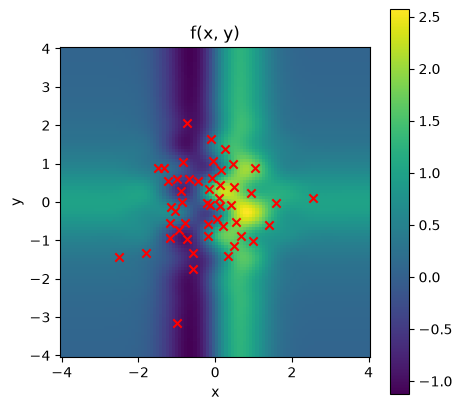

In [3]:
x1 = np.linspace(-4, 4, 100)
x2 = np.linspace(-4, 4, 100)
X1, X2 = np.meshgrid(x1, x2)
X_stack = np.stack([X1, X2], axis = -1)
print(X_stack.shape)
vals = f_np(X_stack)
print(vals.shape)

fig = plt.figure(figsize = (5, 5))
ax = fig.add_subplot()
im = ax.pcolormesh(
    X1, X2, vals,
    shading="auto",
    cmap="viridis",
)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("f(x, y)")
fig.colorbar(im, ax=ax)

ax.scatter(X[:, 0], X[:, 1], color = 'red', marker = 'x')

## Start with JAX only implementation of GPR

In [4]:
def k_base(x1, x2, l):
    """Base OAK"""
    term1 = jnp.exp(-(x1 - x2)**2/(2 * l**2))
    term2 = l * jnp.sqrt(l**2 + 2) / (l**2 + 1) * jnp.exp(-(x1**2 + x2**2)/(2 * (l**2+1)))
    return term1 - term2

def k_add(hyperparams, X1, X2):
    l1, l2, v0, v1, v2 = jnp.exp(jnp.asarray(jax.tree.leaves(hyperparams)))
    k_add0 = v0
    k_add1 = v1 * (k_base(X1[0], X2[0], l1) + k_base(X1[1], X2[1], l2)) 
    k_add2 = v2 * k_base(X1[0], X2[0], l1) * k_base(X1[1], X2[1], l2)
    return k_add0 + k_add1 + k_add2

# Calculate Gram matrix in parallel with JAX vmap
gram_calc = jax.jit(jax.vmap(jax.vmap(k_add, in_axes=(None, None, 0)), in_axes=(None, 0, None)))

In [5]:
# Define priors
hyperparams = {
    "log_l1": jnp.log(0.1),
    "log_l2": jnp.log(0.1),
    "log_v0": jnp.log(1.0),
    "log_v1": jnp.log(1.0),
    "log_v2": jnp.log(1.0)
}

KXX= gram_calc(hyperparams, X, X)
mean = jnp.zeros(N)

print(KXX.shape)
print(jnp.allclose(KXX, KXX.T))
print(mean.shape)

(50, 50)
True
(50,)


In [6]:
# Test locations
x1_test = jnp.linspace(-4, 4, 100)
x2_test = jnp.linspace(-4, 4, 100)
X1_test, X2_test = jnp.meshgrid(x1_test, x2_test)
X_test = jnp.stack([X1_test.ravel(), X2_test.ravel()], axis = -1)
print(X_test.shape)

KXx = gram_calc(hyperparams, X, X_test)
#Kxx = gram_calc(hyperparams, X_test, X_test)
KxX = KXx.T
print(KxX.shape)

(10000, 2)
(10000, 50)


In [7]:
mean_post = KxX @ jnp.linalg.inv(KXX) @ y
#cov_post = Kxx - KxX @ jnp.linalg.inv(KXX) @ KXx

print(mean_post.shape)
#print(cov_post.shape)

(10000,)


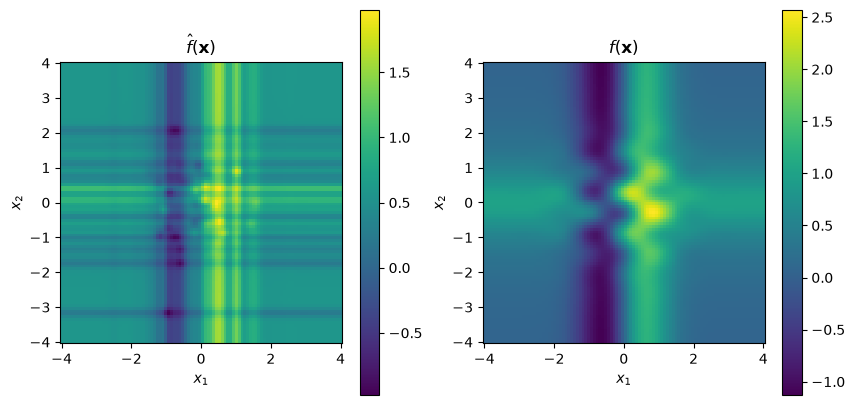

In [8]:
fig = plt.figure(figsize = (10, 5))
ax1 = fig.add_subplot(1, 2, 1)
im = ax1.pcolormesh(
    X1_test, X2_test, mean_post.reshape(100, 100),
    shading="auto",
    cmap="viridis",
)
ax1.set_aspect("equal")
ax1.set_xlabel(r"$x_1$")
ax1.set_ylabel(r"$x_2$")
ax1.set_title(r"$\hat{f}(\mathbf{x})$")
fig.colorbar(im, ax=ax1)

ax2 = fig.add_subplot(1, 2, 2)
im = ax2.pcolormesh(
    X1, X2, vals,
    shading="auto",
    cmap="viridis",
)
ax2.set_aspect("equal")
ax2.set_xlabel(r"$x_1$")
ax2.set_ylabel(r"$x_2$")
ax2.set_title(r"$f(\mathbf{x})$")
fig.colorbar(im, ax=ax2)

Need to optimise hyperparameters using an optimisation scheme. We utilise jax.grad and the L-BFGS-B algorithm to achieve this.

We choose the Bayesian scheme to optimise the log marginal likelihood.

In [9]:
@jax.jit
def nLML(hyperparams, X, y):
    KXX = gram_calc(hyperparams, X, X)
    fit_term = y.T @ jnp.linalg.inv(KXX) @ y
    occam_term = jnp.linalg.slogdet(KXX)[1]
    return 0.5 * (fit_term + occam_term)

val_grad_nLML = jax.jit(jax.value_and_grad(nLML, (0)))

def loss_grad_wrapper(params_list, X, y, structure):
    hyperparams = jax.tree.unflatten(structure, params_list)
    val, grad = val_grad_nLML(hyperparams, X, y)

    return float(val), np.asarray(
        jax.tree.leaves(grad), dtype=np.float64
    )

In [10]:
scipy_initial, structure = jax.tree.flatten(hyperparams)

result = scipy.optimize.minimize(
    loss_grad_wrapper,
    scipy_initial,
    args = (X, y, structure),
    method = 'L-BFGS-B',
    jac = True,
)
print(result.success, result.message, result.fun)

hyperparams_opt = jax.tree.unflatten(structure, result.x)
physical_opt = jax.tree.map(jnp.exp, hyperparams_opt)
print(physical_opt)

True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH -29.686724525837754
{'log_l1': Array(0.55320072, dtype=float64), 'log_l2': Array(0.36800963, dtype=float64), 'log_v0': Array(0.47037562, dtype=float64), 'log_v1': Array(0.22959277, dtype=float64), 'log_v2': Array(0.51988516, dtype=float64)}


In [11]:
KXX_opt = gram_calc(hyperparams_opt, X, X)
KXx_opt = gram_calc(hyperparams_opt, X, X_test)
#Kxx_opt = gram_calc(hyperparams_opt, X_test, X_test)
KxX_opt = KXx_opt.T
mean_opt = KxX_opt @ jnp.linalg.inv(KXX_opt) @ y
#cov_opt = Kxx_opt - KxX_opt @ jnp.linalg.inv(KXX_opt) @ KXx_opt

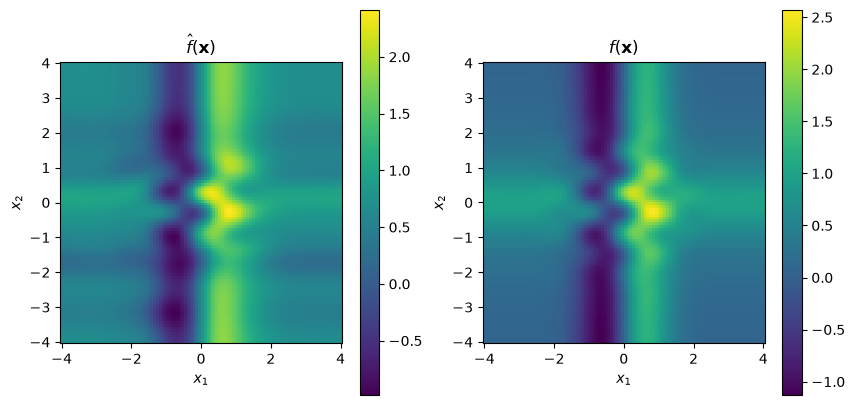

In [12]:
fig = plt.figure(figsize = (10, 5))
ax1 = fig.add_subplot(1, 2, 1)
im = ax1.pcolormesh(
    X1_test, X2_test, mean_opt.reshape(100, 100),
    shading="auto",
    cmap="viridis",
)
ax1.set_aspect("equal")
ax1.set_xlabel(r"$x_1$")
ax1.set_ylabel(r"$x_2$")
ax1.set_title(r"$\hat{f}(\mathbf{x})$")
fig.colorbar(im, ax=ax1)

ax2 = fig.add_subplot(1, 2, 2)
im = ax2.pcolormesh(
    X1, X2, vals,
    shading="auto",
    cmap="viridis",
)
ax2.set_aspect("equal")
ax2.set_xlabel(r"$x_1$")
ax2.set_ylabel(r"$x_2$")
ax2.set_title(r"$f(\mathbf{x})$")
fig.colorbar(im, ax=ax2)

## Using GPJax